# 09 · Image U-Nets, latent diffusion, DiT and reproducible experiments

Trace an image model end to end: residual/time conditioning, patch tokens, stochastic latent caches, Hydra composition and evaluation evidence.

**Prerequisites:** 01, 05–06, 08; image tensors, convolutions and transformer attention.

**By the end:** Inspect U-Net/DiT shapes and gradients; invert train-only latent normalization; sample posterior caches reproducibly; compose custom-data configs; assess reconstruction and generation separately.

Run from top to bottom. Default experiments use CPU, fixed seeds and no downloads. Small trained models illustrate learning; analytic oracles isolate mathematical and solver effects. Neither is an image-quality benchmark.

[Course index](README.md) · [Notation](../docs/23_notation_and_code.md) · [Implementation scope](../docs/15_coverage_and_scope.md)

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display

project = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "diffusion_lab").is_dir())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
torch.set_num_threads(2)
torch.manual_seed(7)
np.random.seed(7)
plt.rcParams.update(
    {
        "figure.figsize": (10, 3.6),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 100,
    }
)
ENABLE_WIDGETS = False  # Set True in Jupyter; static figures work on GitHub.
print(f"PyTorch {torch.__version__}; CPU lesson; seed=7; no automatic downloads.")


def scatter(ax, samples, title, labels=None, limits=(-4.5, 4.5)):
    points = samples.detach().cpu().numpy()
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    ax.scatter(
        points[:, 0],
        points[:, 1],
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=5,
        alpha=0.55,
        linewidths=0,
    )
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", aspect="equal", xlim=limits, ylim=limits)


def saved_gallery(relative, caption):
    path = project / relative
    if not path.is_file():
        raise FileNotFoundError(f"Missing curated course evidence: {relative}")
    print(caption)
    display(Image(filename=str(path)))


def animate_particles(history, name, title, labels=None, limits=(-4.5, 4.5)):
    from matplotlib.animation import FuncAnimation, PillowWriter

    points = history.detach().cpu().numpy()
    indices = np.linspace(0, len(points) - 1, min(32, len(points))).astype(int)
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    dots = ax.scatter(
        *points[0].T,
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=9,
        alpha=0.65,
        linewidths=0,
    )
    ax.set(xlim=limits, ylim=limits, aspect="equal", xlabel="$x_1$", ylabel="$x_2$")

    def update(frame):
        dots.set_offsets(points[indices[frame]])
        ax.set_title(f"{title}: frame {frame + 1}/{len(indices)}")
        return (dots,)

    animation = FuncAnimation(fig, update, frames=len(indices), interval=100)
    folder = project / "assets/teaching/notebooks"
    folder.mkdir(parents=True, exist_ok=True)
    target = folder / f"{name}.gif"
    animation.save(target, writer=PillowWriter(fps=10), dpi=75)
    plt.close(fig)
    display(Image(filename=str(target)))

PyTorch 2.7.1+cu128; CPU lesson; seed=7; no automatic downloads.


## 1. Architecture is separate from the generative process

The same U-Net or transformer can predict epsilon, clean data or a velocity
when its loss, output dimension and sampler agree. Time embedding is required
to distinguish noise levels; residual blocks and normalization modulation
inject conditioning throughout the network.
`ImageUNet` has down/up resolutions, skip connections, FiLM-style time/label
modulation and spatial attention. Its output is zero-initialized; an initial
zero prediction is intentional, not evidence the condition path is unused forever.
**Code:** [image_models.py](../diffusion_lab/image_models.py), [models.py](../diffusion_lab/models.py).

In [2]:
from diffusion_lab.dit import DiT
from diffusion_lab.image_models import ImageUNet

torch.manual_seed(121)
unet = ImageUNet(
    width=16,
    channels=3,
    classes=10,
    channel_mult=(1, 2),
    blocks_per_level=1,
    attention_levels=(1,),
    dropout=0,
)
pixels = torch.randn(2, 3, 16, 16)
time = torch.tensor([0.2, 0.8])
labels = torch.tensor([1, 7])
output = unet(pixels, time, labels)
assert output.shape == pixels.shape
loss = (output - torch.randn_like(output)).square().mean()
optimizer = torch.optim.Adam(unet.parameters(), lr=0.001)
optimizer.zero_grad()
loss.backward()
optimizer.step()
with torch.no_grad():
    first = unet(pixels, time, labels)
    changed = unet(pixels, torch.tensor([0.8, 0.2]), labels)
print("Image shape / parameter count:", output.shape, sum(p.numel() for p in unet.parameters()))
print(
    "Time-dependent RMS change after one update:", (first - changed).square().mean().sqrt().item()
)

Image shape / parameter count: torch.Size([2, 3, 16, 16]) 194723
Time-dependent RMS change after one update: 0.0


## 2. DiT patches and adaLN-Zero

For `[B,C,H,W]` and patch width $p$, patch embedding gives
`[B,N,d]`, $N=(H/p)(W/p)$. Self-attention mixes image tokens; class/time
conditioning modulates LayerNorm and residual gates. Cross-attention to text
is a separate architectural choice, not implied by calling a model DiT.
Unpatchify maps `[B,N,p²*C_out]` back to an image/latent prediction.
adaLN-Zero initially closes residual gates and the final prediction head;
gradients open those paths during training.
**Code:** `DiT.patch_embed`, `DiTBlock`, `unpatchify` in [dit.py](../diffusion_lab/dit.py).

In [3]:
dit = DiT(image_size=16, patch_size=2, width=64, depth=2, heads=4, channels=3, classes=10)
tokens = dit.patch_embed(pixels).flatten(2).transpose(1, 2)
prediction = dit(pixels, time, labels)
print("Patch tokens:", tokens.shape, "output:", prediction.shape)
assert tokens.shape == (2, 64, 64)
torch.testing.assert_close(prediction, torch.zeros_like(prediction), atol=0, rtol=0)
loss = (prediction - torch.randn_like(prediction)).square().mean()
loss.backward()
assert dit.output.weight.grad is not None and dit.output.weight.grad.norm() > 0
print(
    "Zero initial output still permits learning; output-head gradient:",
    dit.output.weight.grad.norm().item(),
)
for patch in [2, 4, 8]:
    token_count = (32 // patch) ** 2
    print(
        f"32px, patch {patch}: {token_count} tokens; {token_count**2} pairwise attention entries/head"
    )

Patch tokens: torch.Size([2, 64, 64]) output: torch.Size([2, 3, 16, 16])
Zero initial output still permits learning; output-head gradient: 0.3993905782699585
32px, patch 2: 256 tokens; 65536 pairwise attention entries/head
32px, patch 4: 64 tokens; 4096 pairwise attention entries/head
32px, patch 8: 16 tokens; 256 pairwise attention entries/head


## 3. Latent diffusion starts with a codec

A frozen encoder gives $q(z|x)$; a decoder turns generated latents back into
pixels. A 256px image encoded with spatial factor 8 becomes `[B,4,32,32]` in
the SD2-family codec used here. Reconstruction quality limits what decoding
can preserve even before the generative model is trained.
The cache stores posterior **mean and standard deviation**, not one frozen
random sample. Sample $z=\mu+\sigma_q\eta$ during training and normalize using
training-only statistics. Validation/test statistics must not determine normalization.
The codec's own scale/shift and cache whitening must be inverted in the right order.
**Code:** `posterior_samples`, `normalize_latents`, `FrozenAutoencoder` in [latents.py](../diffusion_lab/latents.py).

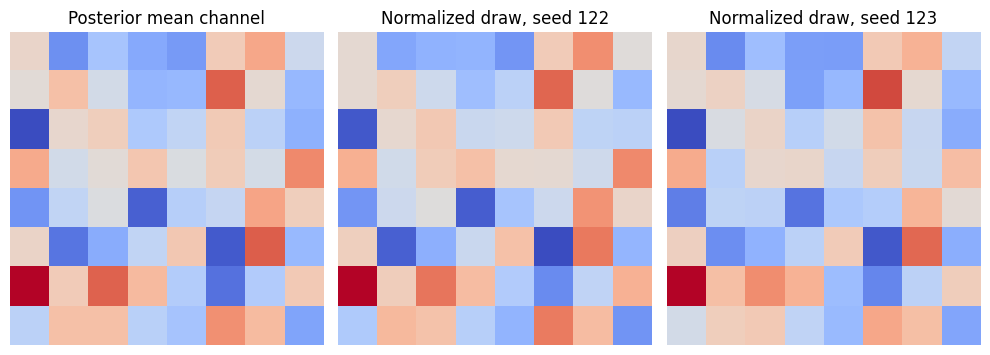

In [4]:
from diffusion_lab.latents import denormalize_latents, normalize_latents, posterior_samples

normalization = {"mean": [0.1, -0.2, 0.3, 0.0], "std": [0.5, 0.8, 1.2, 0.6]}
means = torch.randn(16, 4, 8, 8)
stds = torch.full_like(means, 0.2)
# [B,variants,2*C,H,W]; variant 0 only for this illustrative cache.
moments = torch.cat([means, stds], dim=1)[:, None]
first = posterior_samples(moments, normalization, torch.Generator().manual_seed(122), augment=False)
repeated = posterior_samples(
    moments, normalization, torch.Generator().manual_seed(122), augment=False
)
changed = posterior_samples(
    moments, normalization, torch.Generator().manual_seed(123), augment=False
)
torch.testing.assert_close(first, repeated, atol=0, rtol=0)
assert not torch.equal(first, changed)
torch.testing.assert_close(
    denormalize_latents(normalize_latents(means, normalization), normalization), means
)
fig, axes = plt.subplots(1, 3)
for ax, image, title in zip(
    axes,
    [means[0, 0], first[0, 0], changed[0, 0]],
    ["Posterior mean channel", "Normalized draw, seed 122", "Normalized draw, seed 123"],
    strict=True,
):
    ax.imshow(image, cmap="coolwarm")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Compose a real Hydra recipe

Hydra connects data, architecture, process, sampler and training state.
Compose a toy recipe to see the resolved choices; composition does not train.
For image folders use the dataset's supported layouts and explicit root/classes,
then set channel count and resolution to match the model. The repository
supports custom `_target_` models as documented in the image chapter.
**Code:** [train config](../configs/train.yaml), `make_model` in [models.py](../diffusion_lab/models.py), [ImageDataset](../diffusion_lab/data.py).

In [5]:
from hydra import compose, initialize_config_dir
from omegaconf import OmegaConf

with initialize_config_dir(config_dir=str(project / "configs"), version_base=None):
    config = compose(
        config_name="train", overrides=["experiment=gmm_flow", "device=cpu", "steps=10"]
    )
print(
    OmegaConf.to_yaml(
        {key: config[key] for key in ["data", "model", "process", "sampler", "device", "steps"]}
    )
)

data:
  kind: gmm
  name: ring_gmm
  components: 8
  radius: 3.0
  std: 0.25
model:
  kind: mlp
  width: 128
  depth: 3
process:
  kind: flow
  prediction: velocity
  flow_path: linear
  coupling: independent
  reflow_particles: 4096
sampler:
  method: ode
  steps: 200
  ode_solver: heun
  sde_solver: euler_maruyama
device: cpu
steps: 10



## 5. A GPU codec exercise you explicitly enable

The next cell is off by default and never downloads weights or data.
To inspect **your own local** image and VAE, set `DIFFUSION_NOTEBOOK_VAE` and
`DIFFUSION_NOTEBOOK_IMAGE`, optionally `DIFFUSION_NOTEBOOK_DEVICE=cuda:0`.
The codec remains frozen; this exercise only compares reconstruction to its input.
Use the full training scripts for multi-GPU runs, rather than hiding cluster jobs in a notebook.

In [6]:
vae_path = os.environ.get("DIFFUSION_NOTEBOOK_VAE")
image_path = os.environ.get("DIFFUSION_NOTEBOOK_IMAGE")
if vae_path and image_path:
    from PIL import Image as PILImage
    from PIL import ImageOps

    from diffusion_lab.latents import FrozenAutoencoder

    device = os.environ.get("DIFFUSION_NOTEBOOK_DEVICE", "cpu")
    codec = FrozenAutoencoder(vae_path, device)
    image = ImageOps.fit(
        PILImage.open(image_path).convert("RGB"), (256, 256), method=PILImage.Resampling.BICUBIC
    )
    pixels = torch.from_numpy(np.asarray(image).copy()).permute(2, 0, 1)[None].float() / 127.5 - 1
    with torch.no_grad():
        moments = codec.encode_moments(pixels)
        identity_normalization = {"mean": [0.0] * codec.channels, "std": [1.0] * codec.channels}
        reconstruction = codec.decode(moments[:, : codec.channels], identity_normalization)
    fig, axes = plt.subplots(1, 2)
    for ax, value, title in zip(
        axes, [pixels, reconstruction], ["Input", "Frozen codec reconstruction"], strict=True
    ):
        ax.imshow(((value[0].clamp(-1, 1) + 1) / 2).permute(1, 2, 0))
        ax.set_title(title)
        ax.axis("off")
    plt.show()
else:
    print("Optional codec exercise skipped: set both local VAE and image paths to enable it.")

Optional codec exercise skipped: set both local VAE and image paths to enable it.


## 6. From lesson to a reproducible image experiment

Record: resolved config, source version, data split, training RNG state, model
and inference EMA, codec identity, evaluation seed/counts, guidance, solver
grid and actual NFE. A final weight hash identifies the exact evaluated file;
a mutable `checkpoint.pt` path alone does not.
Report image metrics on decoded/rendered pixels with a fixed feature pipeline.
Latent tensor distance must not be called pixel-image FID.
The public checkout includes curated results, not training caches or weights.
**Read:** [Image training commands](../docs/12_image_experiments.md),
[latent/DiT recipes](../docs/20_latent_diffusion_and_dit.md),
[Slurm templates](../slurm/README.md), [checkpoint manifest](../assets/metadata/checkpoints.json).

cifar10_edm_cfg_final {'fid_2048': 8.969184875488281, 'inception_score_mean': 8.964967727661133, 'real_count': 10000, 'generated_count': 10000}
cifar10_dit_cfg_final {'fid_2048': 8.929252624511719, 'inception_score_mean': 9.26639461517334, 'real_count': 10000, 'generated_count': 10000}
cifar10_flow50_final {'fid_2048': 10.002927780151367, 'inception_score_mean': 9.134531021118164, 'real_count': 10000, 'generated_count': 10000}
Actual trained CIFAR DiT class-conditioned samples; rows are requested classes


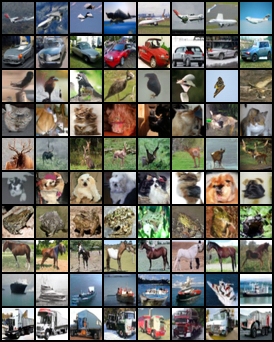

Actual latent face DiT noise interpolation; codec/denoiser identities are recorded in the linked report


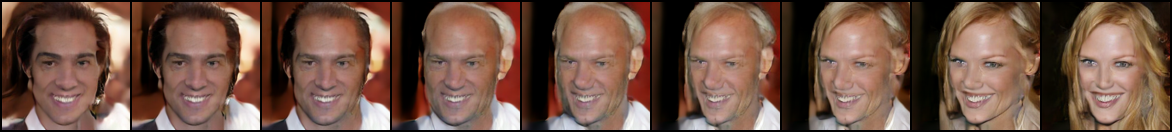

In [7]:
from scripts.asset_layout import experiment_group

for name in ["cifar10_edm_cfg_final", "cifar10_dit_cfg_final", "cifar10_flow50_final"]:
    report = json.loads(
        (project / f"assets/experiments/{experiment_group(name)}/{name}/metrics.json").read_text()
    )
    print(
        name,
        {
            k: report[k]
            for k in ["fid_2048", "inception_score_mean", "real_count", "generated_count"]
        },
    )
saved_gallery(
    "assets/experiments/cifar10/cifar10_dit_cfg_final/classes.png",
    "Actual trained CIFAR DiT class-conditioned samples; rows are requested classes",
)
saved_gallery(
    "assets/experiments/faces/celeba128_latent_dit_final/interpolation.png",
    "Actual latent face DiT noise interpolation; codec/denoiser identities are recorded in the linked report",
)

## Exercises and worked answers

1. Why can a latent denoiser trained from random initialization still depend on external pretraining?
2. How does changing patch width affect token count and attention cost?
3. Why save posterior variance rather than cache one draw per image?

<details><summary>Worked answers</summary>

1. Its frozen encoder/decoder and possibly text encoder were pretrained. Describe those boundaries and unknown overlap with evaluation data.
2. Doubling patch width divides token count by four and full attention entries by sixteen, while losing spatial token granularity. Overall cost also includes projections/MLPs.
3. Repeated posterior draws represent codec uncertainty and require controlled RNG. One cached draw removes that variability from training.

</details>

**Finish the course:** reproduce one small experiment, change one modeling choice,
and report its benefit and limitation using the [evidence protocol](../docs/25_evidence_studies.md).
**Sources:** [Latent diffusion](https://arxiv.org/abs/2112.10752), [DiT](https://arxiv.org/abs/2212.09748).